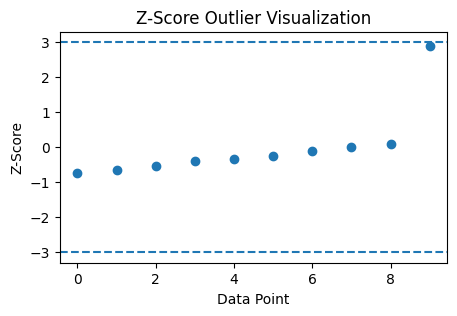

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import zscore

data = np.array([10, 12, 15, 18, 20, 22, 25, 28, 30, 100])

z_scores = zscore(data)
plt.figure(figsize=(5,3))
plt.scatter(range(len(data)), z_scores)

plt.axhline(3, linestyle="--")
plt.axhline(-3, linestyle="--")

plt.xlabel("Data Point")
plt.ylabel("Z-Score")
plt.title("Z-Score Outlier Visualization")

plt.show()

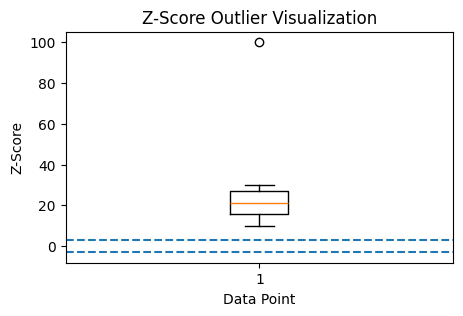

In [3]:
data = np.array([10, 12, 15, 18, 20, 22, 25, 28, 30, 100])

z_scores = zscore(data)
plt.figure(figsize=(5,3))
plt.boxplot(data)
plt.axhline(3, linestyle="--")
plt.axhline(-3, linestyle="--")

plt.xlabel("Data Point")
plt.ylabel("Z-Score")
plt.title("Z-Score Outlier Visualization")

plt.show()

In [4]:
import seaborn as sns
import pandas as pd

In [5]:
df=sns.load_dataset('tips')

In [6]:
df.shape

(244, 7)

{'whiskers': [<matplotlib.lines.Line2D at 0x2077c47fb10>,
 'caps': [<matplotlib.lines.Line2D at 0x2077c47f4d0>,
 'boxes': [<matplotlib.lines.Line2D at 0x2077c47f890>],
 'medians': [<matplotlib.lines.Line2D at 0x2077c47fc50>],
 'fliers': [<matplotlib.lines.Line2D at 0x2077c47f750>],
 'means': []}

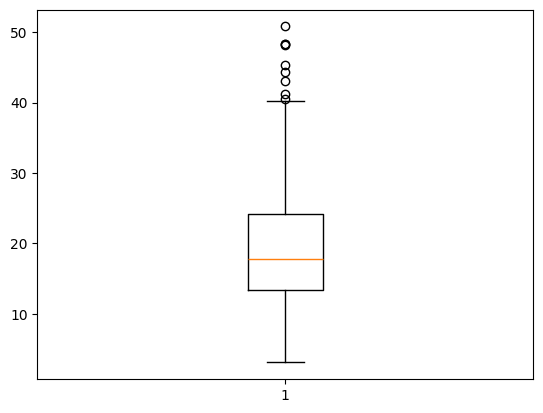

In [7]:
plt.boxplot(df['total_bill'])

In [8]:
df.head()   # top most highest value give krega 

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [9]:
q1=df['total_bill'].quantile(0.25)
q3=df['total_bill'].quantile(0.75)

In [10]:
iqr=q3-q1

In [11]:
iqr

np.float64(10.779999999999998)

In [12]:
lower=q1-1.5*iqr
upper=q3-+1.5*iqr

In [13]:
df1=df[(df['total_bill']<upper)& (df['total_bill']>lower)]

In [14]:
df1.shape

(7, 7)

{'whiskers': [<matplotlib.lines.Line2D at 0x2077c59fc50>,
 'caps': [<matplotlib.lines.Line2D at 0x2077c59fed0>,
 'boxes': [<matplotlib.lines.Line2D at 0x2077c59fb10>],
 'medians': [<matplotlib.lines.Line2D at 0x2077c6ec190>],
 'fliers': [<matplotlib.lines.Line2D at 0x2077c6ec2d0>],
 'means': []}

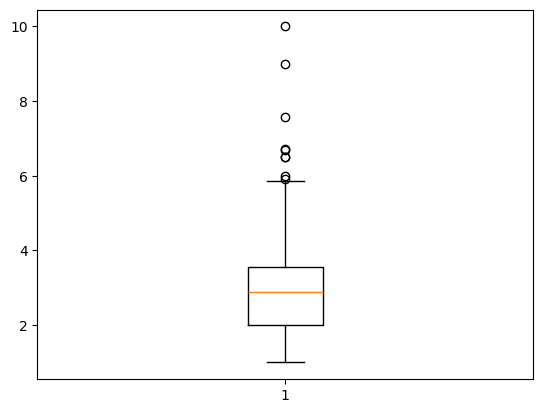

In [15]:
plt.boxplot(df['tip'])

In [16]:
q1=df['tip'].quantile(0.25)
q3=df['tip'].quantile(0.75)
iqr=q3-q1
print('iqr-----',iqr)
lower=q1-1.5*(0.25)
print('lower-----',lower)
upper=q3+1.5*(0.75)
print('upper-----',upper)


iqr----- 1.5625
lower----- 1.625
upper----- 4.6875


{'whiskers': [<matplotlib.lines.Line2D at 0x2077c726850>,
 'caps': [<matplotlib.lines.Line2D at 0x2077c726ad0>,
 'boxes': [<matplotlib.lines.Line2D at 0x2077c726710>],
 'medians': [<matplotlib.lines.Line2D at 0x2077c726d50>],
 'fliers': [<matplotlib.lines.Line2D at 0x2077c726e90>],
 'means': []}

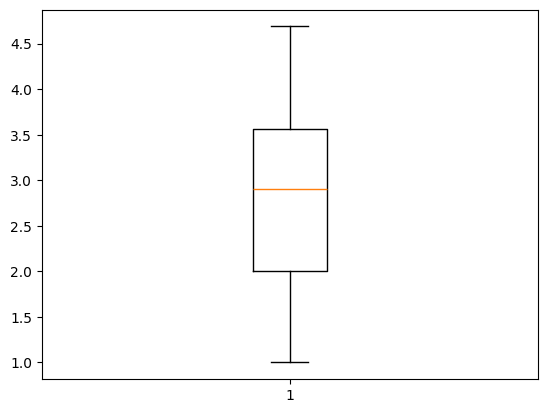

In [17]:
df['tip']=df['tip'].clip(upper=upper)
plt.boxplot(df['tip'])

In [18]:
from sklearn.preprocessing import StandardScaler ,OneHotEncoder,LabelEncoder,MinMaxScaler
from sklearn.compose import ColumnTransformer

In [19]:
df.columns

Index(['total_bill', 'tip', 'sex', 'smoker', 'day', 'time', 'size'], dtype='str')

In [20]:
num_fea=['total_bill',]
cat_fea=['sex', 'smoker']
min_max=['tip']

In [21]:
transformer=ColumnTransformer(
    transformers=[
        ('num',StandardScaler(),num_fea),
        ('min_max',MinMaxScaler(),min_max),
        ('cat',OneHotEncoder(drop='first'),cat_fea),
        ],remainder='passthrough'
    )

In [22]:
transformer.fit_transform(df)


array([[-0.3147113050904943, 0.0027118644067796738, 0.0, ..., 'Sun',
        'Dinner', 2],
       [-1.0632353132988692, 0.17898305084745758, 1.0, ..., 'Sun',
        'Dinner', 3],
       [0.13777989987156145, 0.6779661016949152, 1.0, ..., 'Sun',
        'Dinner', 3],
       ...,
       [0.3246295019205694, 0.2711864406779661, 1.0, ..., 'Sat',
        'Dinner', 2],
       [-0.2212865040659901, 0.2033898305084746, 1.0, ..., 'Sat',
        'Dinner', 2],
       [-0.11322890288102155, 0.5423728813559323, 0.0, ..., 'Thur',
        'Dinner', 2]], shape=(244, 7), dtype=object)

In [23]:
pd.DataFrame(transformer.fit_transform(df),columns=transformer.get_feature_names_out())

,num__total_bill,min_max__tip,cat__sex_Male,cat__smoker_Yes,remainder__day,remainder__time,remainder__size
0,-0.314711,0.002712,0.0,0.0,Sun,Dinner,2
1,-1.063235,0.178983,1.0,0.0,Sun,Dinner,3
2,0.13778,0.677966,1.0,0.0,Sun,Dinner,3
3,0.438315,0.626441,1.0,0.0,Sun,Dinner,2
4,0.540745,0.707797,0.0,0.0,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,1.040511,1.0,1.0,0.0,Sat,Dinner,3
240,0.832275,0.271186,0.0,1.0,Sat,Dinner,2
241,0.32463,0.271186,1.0,1.0,Sat,Dinner,2
242,-0.221287,0.20339,1.0,0.0,Sat,Dinner,2


In [27]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

model = Pipeline([
    ("preprocessor",transformer),
    ("classifier", LogisticRegression())
])

